# Hunga Tonga–Hunga Ha'apai: land and vegetation area over time

Part 2 of the Optical Detectors assignment. The notebook

1. measures the land area of the island from the Google Earth (white-light) JPGs with an HSV colour mask,
2. measures the vegetated area from the Sentinel-2 L2A images with an NDVI mask,
3. compares our spectral index with the one from the Sentinel-2 pipeline, and our land areas with an independent Sentinel-2 estimate.

All paths are relative to the repository root. Results are written to `sentinel-processed/`.

# Setting up the imported packages

In [1]:
import csv
import pathlib
import warnings
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, rgb_to_hsv
from scipy import ndimage
import rasterio
from rasterio.errors import NotGeoreferencedWarning
from rasterio.plot import reshape_as_image

In [2]:
%matplotlib inline

# Define all relevant functions

In [ ]:
EARTH_RADIUS_M = 6_371_000   # mean Earth radius
FOOTER_ROWS = 60             # Google Earth logo and scale bar at the bottom of every JPG


def read_image(path):
    """
    Read a JPG (or any raster) into an array with rasterio.

    Parameters
    ----------
    path : pathlib.Path
        Image file.

    Returns
    -------
    numpy.ndarray
        Image with shape (bands, rows, cols), e.g. (3, 1992, 2382) for the Google Earth JPGs.
    """
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', NotGeoreferencedWarning)   # the JPGs have no map coordinates
        with rasterio.open(path) as src:
            return src.read()                                    # shape (bands, rows, cols)


def scale_bar_length(rgb, threshold=200, rows=40, x_start=1900):
    """
    Measure the length of the Google Earth scale bar in pixels.

    The bar is the longest run of bright pixels in the bottom-right corner of the image.

    Parameters
    ----------
    rgb : numpy.ndarray
        Image with shape (3, rows, cols).
    threshold : float
        Grey level (0-255) above which a pixel counts as part of the bar.
    rows : int
        Number of rows at the bottom of the image to search.
    x_start : int
        First column of the search region.

    Returns
    -------
    length : int
        Bar length in pixels.
    (x0, x1, y) : tuple of int
        End columns and row of the bar in full-image coordinates (for plotting).
    """
    gray = rgb.mean(axis=0)
    corner = gray[-rows:, x_start:]
    bright = corner > threshold
    row = np.argmax(bright.sum(axis=1))           # the row with the most bright pixels
    cols = np.where(bright[row])[0]

    x0 = x_start + cols.min()                     # convert back to full-image coordinates
    x1 = x_start + cols.max()
    y = gray.shape[0] - rows + row
    return x1 - x0 + 1, (x0, x1, y)


def metres_per_pixel(bar_px, bar_m):
    """
    Pixel size of a JPG from its scale bar.

    Parameters
    ----------
    bar_px : int
        Scale bar length in pixels.
    bar_m : float
        Scale bar length in metres (the label under the bar).

    Returns
    -------
    float
        Metres per pixel (the same in x and y).
    """
    return bar_m / bar_px


def jpg_date(path):
    """Date of a Google Earth image from its name, e.g. '2014Feb.jpg' -> 2014-02-01."""
    return datetime.strptime(pathlib.Path(path).stem, '%Y%b')


def s2_date(folder):
    """Date of a Sentinel-2 folder from its name, e.g. 'S2_2017-07-12' -> 2017-07-12."""
    return datetime.strptime(pathlib.Path(folder).name[3:], '%Y-%m-%d')


def read_band(folder, name):
    """
    Read one Sentinel-2 product from a date folder.

    Parameters
    ----------
    folder : pathlib.Path
        Date folder, e.g. sentinel-data/S2_2017-07-12.
    name : str
        Product name between 'Sentinel-2_L2A_' and '.tiff', e.g. 'B04_Raw' or 'NDVI'.

    Returns
    -------
    data : numpy.ndarray
        float64 array, (rows, cols) for single bands or (bands, rows, cols) for colour products.
    meta : dict
        'res' (degrees per pixel in x and y), 'bounds' (degrees) and 'profile'
        (rasterio profile, used to write masks with the same georeferencing).
    """
    with rasterio.open(folder / f'Sentinel-2_L2A_{name}.tiff') as src:
        data = src.read().astype(np.float64)
        meta = {'res': src.res, 'bounds': src.bounds, 'profile': src.profile}
    return (data[0] if data.shape[0] == 1 else data), meta


def pixel_size_m(res, bounds):
    """
    Convert the angular pixel size of an EPSG:4326 image into metres.

    One degree of latitude is R * pi / 180 metres everywhere, while one degree of longitude
    shrinks by cos(latitude). The latitude used is the centre of the image.

    Parameters
    ----------
    res : tuple of float
        Pixel size (x, y) in degrees, from src.res.
    bounds : rasterio.coords.BoundingBox
        Image boundaries in degrees, from src.bounds.

    Returns
    -------
    dx, dy : float
        Pixel width (east-west) and height (north-south) in metres.
    """
    latitude = np.deg2rad((bounds.top + bounds.bottom) / 2)
    dx = EARTH_RADIUS_M * np.deg2rad(res[0]) * np.cos(latitude)
    dy = EARTH_RADIUS_M * np.deg2rad(res[1])
    return dx, dy


def normalized_difference(a, b):
    """
    Normalised difference index (a - b) / (a + b), e.g. NDVI = (B08 - B04) / (B08 + B04).

    Parameters
    ----------
    a, b : numpy.ndarray
        Reflectance bands with the same shape.

    Returns
    -------
    numpy.ndarray
        Index between -1 and 1, NaN where a + b = 0 (e.g. no-data pixels).
    """
    a = a.astype(np.float64)
    b = b.astype(np.float64)
    total = a + b
    with np.errstate(invalid='ignore', divide='ignore'):
        index = (a - b) / total
    index[total == 0] = np.nan
    return index


def read_ndvi(folder):
    """
    NDVI = (B08 - B04) / (B08 + B04) of one Sentinel-2 date folder.

    Returns
    -------
    ndvi : numpy.ndarray
        NDVI values (-1 to 1, NaN for no data), shape (rows, cols).
    meta : dict
        Metadata of the B04 band (see read_band).
    """
    red, meta = read_band(folder, 'B04_Raw')
    nir, _ = read_band(folder, 'B08_Raw')
    return normalized_difference(nir, red), meta


def remove_small_regions(mask, min_size):
    """
    Remove connected True regions smaller than min_size pixels from a boolean mask.

    Parameters
    ----------
    mask : numpy.ndarray of bool
        Mask to clean.
    min_size : int
        Smallest region (in pixels) that is kept.

    Returns
    -------
    numpy.ndarray of bool
        The mask with only the regions of at least min_size pixels.
    """
    regions, _ = ndimage.label(mask)
    sizes = np.bincount(regions.ravel())
    sizes[0] = 0                                    # label 0 is the background
    return (sizes >= min_size)[regions]


def area_from_mask(mask, pixel_area):
    """
    Area covered by a boolean mask.

    Parameters
    ----------
    mask : numpy.ndarray of bool
        True for the pixels to count.
    pixel_area : float
        Area of one pixel in m².

    Returns
    -------
    float
        Area in m².
    """
    return np.count_nonzero(mask) * pixel_area


def save_mask(mask, path, profile=None):
    """
    Save a boolean mask as 0/1.

    Parameters
    ----------
    mask : numpy.ndarray of bool
        Mask to save.
    path : pathlib.Path
        Output file. Use '.tif' together with `profile`, '.png' otherwise.
    profile : dict, optional
        rasterio profile of the source image. If given, the mask is written as a GeoTIFF with
        the same georeferencing; if not (the JPGs), it is written as a PNG.
    """
    path = pathlib.Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if profile is None:
        plt.imsave(path, mask.astype(np.uint8), cmap='gray', vmin=0, vmax=1)
        return
    profile = {key: value for key, value in profile.items() if key != 'photometric'}
    profile.update(driver='GTiff', count=1, dtype='uint8', nodata=None)
    with rasterio.open(path, 'w', **profile) as dst:
        dst.write(mask.astype(np.uint8), 1)


def land_mask_hsv(rgb, h_range, s_range=(0, 1), v_range=(0, 1), crop_bottom=FOOTER_ROWS,
                  open_iterations=0, min_region=0, max_hole=0):
    """
    Separate land from sea in a Google Earth image using HSV thresholds.

    Parameters
    ----------
    rgb : numpy.ndarray
        Image with shape (3, rows, cols), values 0-255.
    h_range, s_range, v_range : tuple of float
        (min, max) of hue, saturation and value (all 0-1) that count as land. The hue range
        has to be given; saturation and value accept every pixel by default.
    crop_bottom : int
        Rows at the bottom of the image to ignore (Google Earth logo and scale bar).
    open_iterations : int
        Iterations of binary opening, which removes specks and thin lines (waves, sun glint,
        text labels) narrower than about 2 * open_iterations pixels. 0 skips this step.
    min_region : int
        Connected land regions smaller than this many pixels are removed (clouds, shadows,
        leftover specks). 0 keeps every region.
    max_hole : int
        Holes inside the land of at most this many pixels are filled. Larger holes, such as
        the crater lake, stay water. 0 fills no holes.

    Returns
    -------
    numpy.ndarray of bool
        True for land pixels, shape (rows, cols).
    """
    hsv = rgb_to_hsv(reshape_as_image(rgb) / 255)   # shape (rows, cols, 3), values 0-1

    land = np.ones(hsv.shape[:2], dtype=bool)
    for channel, (low, high) in enumerate([h_range, s_range, v_range]):
        land &= (hsv[..., channel] >= low) & (hsv[..., channel] <= high)

    land[-crop_bottom:] = False                     # Google Earth logo and scale bar

    if open_iterations:
        land = ndimage.binary_opening(land, iterations=open_iterations)

    if min_region:
        land = remove_small_regions(land, min_region)

    if max_hole:
        holes, _ = ndimage.label(ndimage.binary_fill_holes(land) & ~land)
        sizes = np.bincount(holes.ravel())
        sizes[0] = 0                                # label 0 is everything that is not a hole
        land = land | ((sizes > 0) & (sizes <= max_hole))[holes]

    return land


def vegetation_mask(ndvi, threshold):
    """
    Vegetation mask from an NDVI image.

    Parameters
    ----------
    ndvi : numpy.ndarray
        NDVI values (-1 to 1, NaN for no data).
    threshold : float
        Pixels with NDVI above this value count as vegetation.

    Returns
    -------
    numpy.ndarray of bool
        True for vegetation (NaN pixels are False).
    """
    return ndvi > threshold


def land_mask_ndwi(ndwi, threshold=0.0, min_region=0):
    """
    Land mask from NDWI = (B03 - B08) / (B03 + B08): water has NDWI > 0, land NDWI < 0.

    Parameters
    ----------
    ndwi : numpy.ndarray
        NDWI values (-1 to 1, NaN for no data).
    threshold : float
        Pixels with NDWI below this value count as land.
    min_region : int
        Connected land regions smaller than this many pixels are removed (e.g. clouds, which
        also have NDWI close to 0). 0 keeps every region.

    Returns
    -------
    numpy.ndarray of bool
        True for land (NaN pixels are False).
    """
    land = ndwi < threshold
    if min_region:
        land = remove_small_regions(land, min_region)
    return land


def pipeline_vegetation_mask(ndvi_rgb):
    """
    Vegetation mask from the Sentinel-2 pipeline NDVI product.

    The pipeline file is a colour visualisation of NDVI (3 bands, 0-1), not the index itself,
    so vegetation has to be recovered from the colours. Its colour scale goes from grey (water)
    through cream and yellow to darker and darker green, and green becomes the strongest channel
    at NDVI of about 0.125. A pixel counts as vegetation where green is the strongest channel,
    so this mask corresponds to a fixed threshold of NDVI >= 0.125.

    Parameters
    ----------
    ndvi_rgb : numpy.ndarray
        Pipeline NDVI image with shape (3, rows, cols).

    Returns
    -------
    numpy.ndarray of bool
        True where green is the strongest colour channel.
    """
    red, green, blue = ndvi_rgb
    return (green > red) & (green > blue)


def compare_masks(mine, theirs):
    """
    Pixel-by-pixel comparison of two boolean masks with the same shape.

    Parameters
    ----------
    mine, theirs : numpy.ndarray of bool
        Our mask and the reference mask.

    Returns
    -------
    dict
        'agreement' (fraction of pixels where both masks agree), 'only_mine' and
        'only_theirs' (pixel counts where only one mask is True) and 'iou'
        (intersection over union of the True pixels).
    """
    both = mine & theirs
    either = mine | theirs
    return {
        'agreement': np.mean(mine == theirs),
        'only_mine': int(np.sum(mine & ~theirs)),
        'only_theirs': int(np.sum(~mine & theirs)),
        'iou': both.sum() / either.sum() if either.any() else np.nan,
    }

# Code execution starts here.

## 0. Define the working directory and inputs
`EXCLUDE` lists the Google Earth images left out of the land-area analysis (see Section 3.4).

In [4]:
here = pathlib.Path('.')
jpg_dir = here / 'sentinel-data' / 'White_light'
s2_dir = here / 'sentinel-data'
out_dir = here / 'sentinel-processed'
out_dir.mkdir(exist_ok=True)

SCALE_BAR_M = 600          # every Google Earth scale bar is labelled 600 m
EXCLUDE = {'2021Dec'}      # eruption plume hides the island

jpg_files = sorted(jpg_dir.glob('*.jpg'), key=jpg_date)
s2_folders = sorted(s2_dir.glob('S2_*'), key=s2_date)

print("Google Earth:", [f.stem for f in jpg_files])
print("Sentinel-2:  ", [f.name for f in s2_folders])

Google Earth: ['2014Feb', '2016May', '2020Nov', '2021Dec', '2022Jan', '2023Oct']
Sentinel-2:   ['S2_2017-07-12', 'S2_2018-07-12', 'S2_2019-07-12']


## 1. Pixel-to-metre ratio of the Google Earth images
Each JPG has a scale bar in the bottom-right corner labelled 600 m. Its length in pixels gives the pixel size,
which is the same in x and y, so the area of one pixel is $(\mathrm{m/px})^2$.

### 1.1. Find the scale bar in one image

310 px from x = 2067 to 2376 at y = 1987


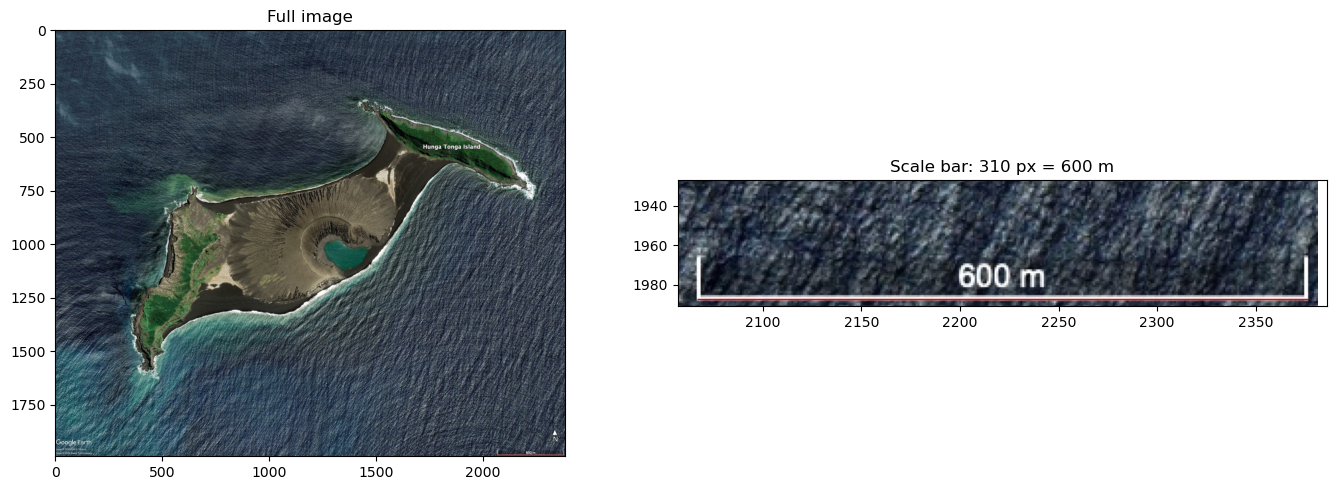

In [5]:
path = jpg_dir / '2020Nov.jpg'
rgb = read_image(path)
length, (x0, x1, y) = scale_bar_length(rgb)
print(f"{length} px from x = {x0} to {x1} at y = {y}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax in axes:
    ax.imshow(reshape_as_image(rgb))
    ax.plot([x0, x1], [y, y], color='red', lw=1)

axes[1].set_xlim(x0 - 10, x1 + 10)
axes[1].set_ylim(rgb.shape[1] - 1, y - 60)        # y increases downwards in image coordinates
axes[0].set_title('Full image')
axes[1].set_title(f'Scale bar: {length} px = {SCALE_BAR_M} m')

plt.tight_layout()
plt.show()

### 1.2. Pixel size of every image

In [6]:
jpg_scale = {}   # image name -> metres per pixel

for file in jpg_files:
    bar_px, _ = scale_bar_length(read_image(file))
    jpg_scale[file.stem] = metres_per_pixel(bar_px, SCALE_BAR_M)
    print(f"{file.stem:8} bar {bar_px:4d} px -> {jpg_scale[file.stem]:.3f} m/px, "
          f"{jpg_scale[file.stem] ** 2:.3f} m² per pixel")

2014Feb  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2016May  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2020Nov  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2021Dec  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2022Jan  bar  310 px -> 1.935 m/px, 3.746 m² per pixel
2023Oct  bar  310 px -> 1.935 m/px, 3.746 m² per pixel


TODO: comment on the result (are all bars the same length? how precise is the measurement, e.g. ±1 px on the bar → ±? % on the area?).

## 2. Pixel-to-metre ratio of the Sentinel-2 images
The Sentinel-2 products are in EPSG:4326, so `src.res` gives the pixel size in degrees. With the latitude $\phi$ at the centre of the image (from `src.bounds`)
and $R_\oplus$ the Earth's radius,

$$\Delta y = R_\oplus\,\Delta\phi, \qquad \Delta x = R_\oplus \cos\phi\,\Delta\lambda,$$

with $\Delta\phi$ and $\Delta\lambda$ in radians. The images are resampled to a nominal 10 m.

In [7]:
s2_pixel_area = {}   # folder name -> m² per pixel

for folder in s2_folders:
    _, meta = read_band(folder, 'B04_Raw')
    dx, dy = pixel_size_m(meta['res'], meta['bounds'])
    s2_pixel_area[folder.name] = dx * dy
    print(f"{folder.name}: res {meta['res'][0]:.3e}° x {meta['res'][1]:.3e}° -> "
          f"{dx:.2f} m x {dy:.2f} m = {dx * dy:.1f} m²")

S2_2017-07-12: res 8.989e-05° x 8.413e-05° -> 9.36 m x 9.35 m = 87.6 m²
S2_2018-07-12: res 8.989e-05° x 8.413e-05° -> 9.36 m x 9.35 m = 87.6 m²
S2_2019-07-12: res 8.989e-05° x 8.413e-05° -> 9.36 m x 9.35 m = 87.6 m²


TODO: comment on the result: compare with the nominal 10 m, and say whether the variation of latitude across the image matters.

## 3. Land area from the Google Earth images (HSV mask)
In HSV space, sea and land separate mainly by hue (blue water vs brown/green land). The mask keeps the pixels inside a hue range
and then cleans the result: a binary opening removes specks and thin lines, connected regions smaller than `min_region` pixels
are removed, and holes up to `max_hole` pixels are filled. The hue range is chosen on 2020Nov and the same settings are applied to every image.

### 3.1. Explore the HSV values of one image

In [ ]:
H_RANGE = (0, 0.40)   # hue range that counts as land, used for every image

rgb = read_image(jpg_dir / '2020Nov.jpg')
hsv = rgb_to_hsv(reshape_as_image(rgb) / 255)   # shape (rows, cols, 3), values 0-1
hsv = hsv[:-FOOTER_ROWS]                        # drop the logo and scale bar rows

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for ax, channel, name in zip(axes[0], range(3), ['Hue', 'Saturation', 'Value']):
    im = ax.imshow(hsv[..., channel], cmap='twilight' if channel == 0 else 'gray', vmin=0, vmax=1)
    ax.set_title(name)
    fig.colorbar(im, ax=ax, fraction=0.04)

for ax, channel, name in zip(axes[1], range(3), ['Hue', 'Saturation', 'Value']):
    ax.hist(hsv[..., channel].ravel(), bins=200, range=(0, 1), log=True)
    ax.set_xlabel(name)
axes[1, 0].axvline(H_RANGE[1], color='red', ls='--', lw=2, label=f'land/sea cut (H = {H_RANGE[1]})')
axes[1, 0].legend()
axes[1, 0].set_ylabel('Pixels')

plt.tight_layout()
plt.show()

TODO: explain the chosen ranges.

### 3.2. Apply the mask to one image

In [ ]:
CLEAN = dict(open_iterations=2, min_region=10_000, max_hole=5_000)   # used for every image

EXAMPLE = '2022Jan'
rgb = read_image(jpg_dir / f'{EXAMPLE}.jpg')
raw = land_mask_hsv(rgb, H_RANGE)
land = land_mask_hsv(rgb, H_RANGE, **CLEAN)
image = reshape_as_image(rgb)

regions, n_regions = ndimage.label(land)
region_labels = range(1, n_regions + 1)
sizes = ndimage.sum(land, regions, region_labels)
centres = ndimage.center_of_mass(land, regions, region_labels)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
axes[0].imshow(np.ma.masked_array(image[..., 0], mask=~raw))
axes[0].set_title(f'Hue only: {raw.sum()} px')
axes[1].imshow(np.ma.masked_array(image[..., 0], mask=~land))
axes[1].set_title(f'Cleaned: {land.sum()} px')
axes[2].imshow(image)
axes[2].contour(land, levels=[0.5], colors='red', linewidths=0.8)
for number, (row, col) in zip(region_labels, centres):
    axes[2].annotate(str(number), (col, row), color='yellow', fontsize=14, fontweight='bold')
axes[2].set_title(f'Cleaned outline on {EXAMPLE}')

plt.tight_layout()
plt.show()

change = land.astype(int) - raw.astype(int)
print(f"hue only {raw.sum()} px, cleaned {land.sum()} px out of {land.size}: "
      f"{np.sum(change < 0)} px removed, {np.sum(change > 0)} px filled")
for number, size in zip(region_labels, sizes):
    print(f"region {number}: {size:8.0f} px = {size * jpg_scale[EXAMPLE] ** 2 / 1e6:.4f} km²")

# the regions that min_region compares against: after the opening, before any region is removed
opened = land_mask_hsv(rgb, H_RANGE, open_iterations=CLEAN['open_iterations'])
opened_sizes = np.sort(np.bincount(ndimage.label(opened)[0].ravel())[1:])[::-1]
print(f"largest regions after the opening (min_region = {CLEAN['min_region']}):", opened_sizes[:8])


### 3.3. Land area of every image

In [11]:
land_files = [file for file in jpg_files if file.stem not in EXCLUDE]
land_area = {}   # image name -> land area in m²

for file in land_files:
    rgb = read_image(file)
    land = land_mask_hsv(rgb, H_RANGE, **CLEAN)
    land_area[file.stem] = area_from_mask(land, jpg_scale[file.stem] ** 2)
    save_mask(land, out_dir / f"{file.stem}_land_mask.png")

### 3.4. Excluding 2021Dec
TODO: explain why `2021Dec` is excluded (eruption plume covers the island), with the image as evidence.

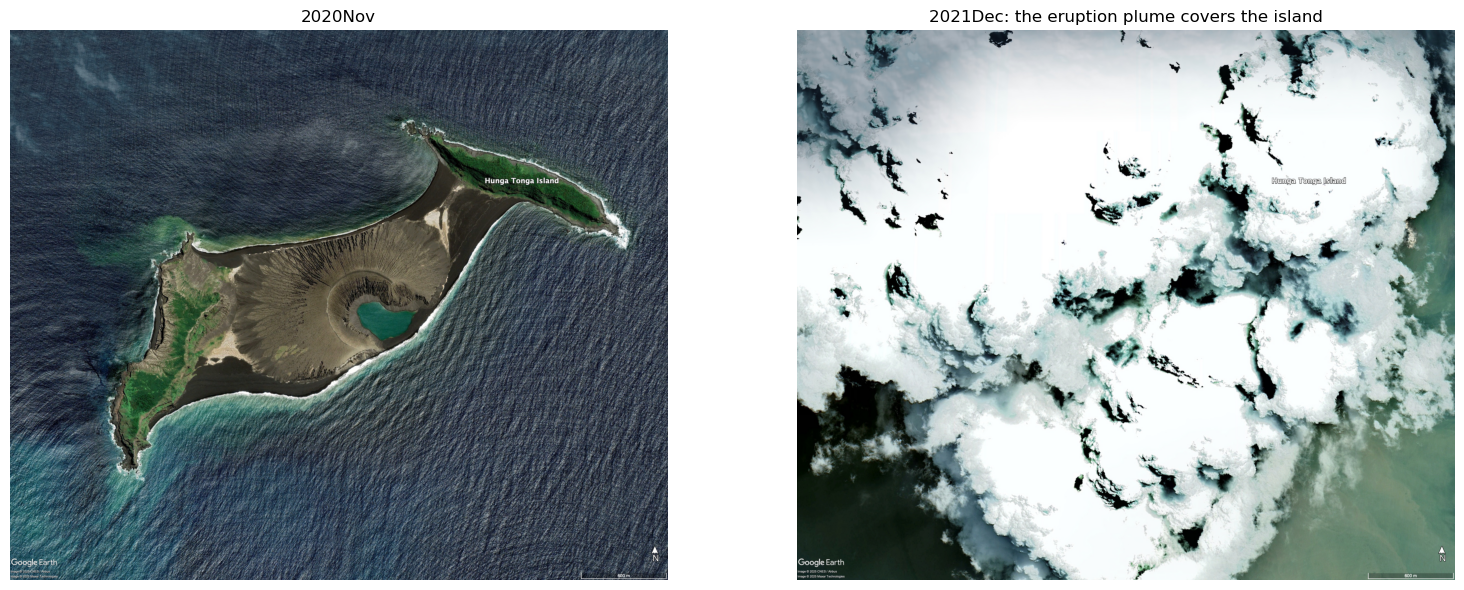

In [12]:
def show_jpg(name, ax=None):
    """Show one Google Earth image by name, e.g. show_jpg('2021Dec')."""
    if ax is None:
        _, ax = plt.subplots(figsize=(9, 6))
    ax.imshow(reshape_as_image(read_image(jpg_dir / f'{name}.jpg')))
    ax.set_title(name)
    ax.axis('off')
    return ax


fig, axes = plt.subplots(1, 2, figsize=(16, 6))
show_jpg('2020Nov', axes[0])
show_jpg('2021Dec', axes[1])
axes[1].set_title('2021Dec: the eruption plume covers the island')
plt.tight_layout()
plt.show()

### 3.5. Land area over time

In [ ]:
ERUPTION = datetime(2022, 1, 15)

names = list(land_area)
# The file names only give the month, so jpg_date() returns the 1st. 2022Jan was taken after the
# eruption (exact day unknown), so it is dated at the end of January instead (also in areas.csv).
jpg_dates = {name: jpg_date(name) for name in names}
jpg_dates['2022Jan'] = datetime(2022, 1, 31)
dates = [jpg_dates[name] for name in names]
areas_km2 = [land_area[name] / 1e6 for name in names]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(dates, areas_km2, 'o-')
for date, area, name in zip(dates, areas_km2, names):
    ax.annotate(name, (date, area), textcoords='offset points', xytext=(5, 5))
ax.axvline(ERUPTION, color='red', ls='--', label='Eruption, 15 January 2022')
ax.set_xlabel('Date')
ax.set_ylabel('Land area (km²)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

TODO: discuss the evolution of the land area.

## 4. Vegetated area from Sentinel-2 (NDVI mask)
NDVI is computed from the bottom-of-atmosphere reflectance of the red (B04) and near-infrared (B08) bands:

$$\mathrm{NDVI} = \frac{B08 - B04}{B08 + B04}.$$

Vegetation reflects strongly in the NIR and absorbs red light, so it has high NDVI. Water is negative and bare rock/ash is close to 0.
The three Sentinel-2 dates (July 2017, 2018 and 2019) are all before the eruption.

### 4.1. NDVI of one date

In [ ]:
folder = s2_folders[0]
ndvi, meta = read_ndvi(folder)

true_color, _ = read_band(folder, 'True_color')   # shape (3, rows, cols), values 0-1

fig, axes = plt.subplots(1, 3, figsize=(18, 5), gridspec_kw={'width_ratios': [1, 1.2, 1]})
axes[0].imshow(reshape_as_image(true_color))
axes[0].set_title(f'{folder.name}: true colour')
im = axes[1].imshow(ndvi, cmap='RdYlGn', vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[1], label='NDVI')
axes[1].set_title('NDVI = (B08 - B04) / (B08 + B04)')
for ax in axes[:2]:
    ax.axis('off')

axes[2].hist(ndvi[~np.isnan(ndvi)], bins=200, range=(-1, 1), log=True)
axes[2].set_xlabel('NDVI')
axes[2].set_ylabel('Pixels')
axes[2].set_title('NDVI histogram (no-data pixels left out)')

plt.tight_layout()
plt.show()

print(f"{np.isnan(ndvi).sum()} no-data pixels out of {ndvi.size}")

### 4.2. Choosing the NDVI threshold
TODO: justify the threshold (literature values, the histogram, the true-colour image).

In [15]:
NDVI_THRESHOLD = 0.5

### 4.3. Vegetated area of every date

In [ ]:
ndvi_by_date = {}   # folder name -> NDVI image, reused in Section 5
veg_area = {}       # folder name -> vegetated area in m²

for folder in s2_folders:
    ndvi, meta = read_ndvi(folder)
    ndvi_by_date[folder.name] = ndvi
    vegetation = vegetation_mask(ndvi, NDVI_THRESHOLD)
    veg_area[folder.name] = area_from_mask(vegetation, s2_pixel_area[folder.name])
    save_mask(vegetation, out_dir / f"{folder.name}_vegetation_mask.tif", meta['profile'])

### 4.4. Vegetated area over time

In [17]:
names = list(veg_area)
dates = [s2_date(name) for name in names]
areas_km2 = [veg_area[name] / 1e6 for name in names]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(dates, areas_km2, 'o-', color='green')
for date, area in zip(dates, areas_km2):
    ax.annotate(f'{area:.3f} km²', (date, area), textcoords='offset points', xytext=(5, 5))
ax.set_xticks(dates)
ax.set_xticklabels([date.strftime('%Y-%m-%d') for date in dates])
ax.set_ylim(bottom=0)
ax.set_xlabel('Date')
ax.set_ylabel('Vegetated area (km²)')
ax.set_title(f'Vegetated area from Sentinel-2 (NDVI > {NDVI_THRESHOLD})')
ax.grid(alpha=0.3)
plt.show()

for name, area in zip(names, areas_km2):
    print(f"{name}: {area:.4f} km²")

S2_2017-07-12: 0.3887 km²
S2_2018-07-12: 0.4808 km²
S2_2019-07-12: 0.5285 km²


TODO: discuss the evolution of the vegetated area.

# Compare and Contrast

## 5. Comparison with the Sentinel-2 pipeline and between data sets
### 5.1. Our NDVI vs the pipeline NDVI
The pipeline `NDVI.tiff` is a 3-band colour visualisation (values 0–1) of the index, not the index itself.
The values cannot be compared directly, so we compare the vegetation masks pixel by pixel and the vegetated areas they give.

In [ ]:
PIPELINE_THRESHOLD = 0.125   # green is the strongest channel from this NDVI step on (see pipeline_vegetation_mask)

folder = s2_folders[0]
pipeline_rgb, _ = read_band(folder, 'NDVI')   # shape (3, rows, cols)
ndvi = ndvi_by_date[folder.name]

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].imshow(reshape_as_image(pipeline_rgb))
axes[0].set_title(f'{folder.name}: pipeline NDVI.tiff (colour visualisation)')
im = axes[1].imshow(ndvi, cmap='RdYlGn', vmin=-1, vmax=1)
fig.colorbar(im, ax=axes[1], label='NDVI')
axes[1].set_title(f'{folder.name}: our NDVI from B04 and B08')
for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
pipeline_masks = {}      # folder name -> vegetation mask from the pipeline colours
pipeline_veg_area = {}   # folder name -> vegetated area in m² from the pipeline colours

print(f"{'date':13} {'threshold':>9} {'ours (km²)':>10} {'pipeline (km²)':>14} "
      f"{'agreement':>9} {'only ours':>9} {'only pipeline':>13} {'IoU':>6}")
for folder in s2_folders:
    ndvi = ndvi_by_date[folder.name]
    pixel_area = s2_pixel_area[folder.name]

    theirs = pipeline_vegetation_mask(read_band(folder, 'NDVI')[0])
    pipeline_masks[folder.name] = theirs
    pipeline_veg_area[folder.name] = area_from_mask(theirs, pixel_area)

    # our mask at our own threshold, and at the threshold the pipeline mask corresponds to
    for threshold in (NDVI_THRESHOLD, PIPELINE_THRESHOLD):
        mine = vegetation_mask(ndvi, threshold)
        result = compare_masks(mine, theirs)
        print(f"{folder.name:13} {threshold:9.3f} {area_from_mask(mine, pixel_area) / 1e6:10.4f} "
              f"{pipeline_veg_area[folder.name] / 1e6:14.4f} {result['agreement']:9.4f} "
              f"{result['only_mine']:9d} {result['only_theirs']:13d} {result['iou']:6.3f}")

In [ ]:
folder = s2_folders[0]
ndvi = ndvi_by_date[folder.name]
theirs = pipeline_masks[folder.name]

# 0 = neither, 1 = both, 2 = only ours, 3 = only the pipeline
classes = ListedColormap(['white', 'green', 'tab:blue', 'tab:red'])
labels = ['neither', 'both', 'only ours', 'only pipeline']

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, threshold in zip(axes, (NDVI_THRESHOLD, PIPELINE_THRESHOLD)):
    mine = vegetation_mask(ndvi, threshold)
    category = np.select([mine & theirs, mine & ~theirs, ~mine & theirs], [1, 2, 3], default=0)
    ax.imshow(category, cmap=classes, vmin=-0.5, vmax=3.5, interpolation='nearest')
    ax.set_title(f'{folder.name}: ours (NDVI > {threshold}) vs pipeline')
    ax.axis('off')
handles = [plt.Rectangle((0, 0), 1, 1, facecolor=classes(i), edgecolor='black') for i in range(4)]
fig.legend(handles, labels, loc='lower center', ncol=4)

plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

TODO: explain the differences quantitatively. Points to consider: the colour ramp quantises NDVI into steps,
the pipeline may use different thresholds/colour breaks, the raw band values are clipped to 0–1,
and pixels at the coast are mixed land/sea.

### 5.2. Sensitivity to the NDVI threshold

In [ ]:
thresholds = np.linspace(0, 0.8, 81)

fig, ax = plt.subplots(figsize=(10, 5))
for name, ndvi in ndvi_by_date.items():
    areas_km2 = [area_from_mask(vegetation_mask(ndvi, t), s2_pixel_area[name]) / 1e6 for t in thresholds]
    line, = ax.plot(thresholds, areas_km2, label=name)
    ax.plot(PIPELINE_THRESHOLD, pipeline_veg_area[name] / 1e6, 'o', color=line.get_color())

ax.axvline(NDVI_THRESHOLD, color='black', ls='--', label=f'our threshold ({NDVI_THRESHOLD})')
ax.axvline(PIPELINE_THRESHOLD, color='grey', ls=':', label=f'pipeline mask ({PIPELINE_THRESHOLD}), dots = pipeline area')
ax.set_xlabel('NDVI threshold')
ax.set_ylabel('Vegetated area (km²)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

TODO: how much does the vegetated area depend on the threshold?

### 5.3. Land area: Sentinel-2 vs Google Earth
An independent land-area estimate from Sentinel-2 uses NDWI = (B03 − B08) / (B03 + B08). Water has NDWI > 0.
These points are plotted together with the Google Earth series from Section 3.5.

In [ ]:
# Bare ash has NDWI close to 0, so a threshold of 0 cuts through the cone. The NDWI histogram has
# its minimum between the ash peak (~0) and the sea peak (> 0.3) at about 0.1 on all three dates.
NDWI_THRESHOLD = 0.1
S2_MIN_REGION = 3000   # px; the clouds in 2019 are up to ~2750 px, the island ~32 000 px

s2_land_area = {}   # folder name -> land area in m²

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for folder in s2_folders:
    green, meta = read_band(folder, 'B03_Raw')
    nir, _ = read_band(folder, 'B08_Raw')
    ndwi = normalized_difference(green, nir)
    land = land_mask_ndwi(ndwi, NDWI_THRESHOLD, S2_MIN_REGION)
    s2_land_area[folder.name] = area_from_mask(land, s2_pixel_area[folder.name])
    save_mask(land, out_dir / f"{folder.name}_land_mask.tif", meta['profile'])
    axes[0].hist(ndwi[~np.isnan(ndwi)], bins=150, range=(-0.6, 0.9), histtype='step', log=True, label=folder.name)

axes[0].axvline(NDWI_THRESHOLD, color='black', ls='--', label=f'threshold ({NDWI_THRESHOLD})')
axes[0].set_xlabel('NDWI')
axes[0].set_ylabel('Pixels')
axes[0].set_title('NDWI histograms: ash/vegetation (left) and sea (right)')
axes[0].legend()

ge_names = list(land_area)
axes[1].plot([jpg_dates[name] for name in ge_names],
             [land_area[name] / 1e6 for name in ge_names], 'o-', label='Google Earth (HSV mask)')
axes[1].plot([s2_date(name) for name in s2_land_area], [area / 1e6 for area in s2_land_area.values()],
             's-', label=f'Sentinel-2 (NDWI < {NDWI_THRESHOLD})')
axes[1].axvline(ERUPTION, color='red', ls='--', label='Eruption, 15 January 2022')
axes[1].set_xlabel('Date')
axes[1].set_ylabel('Land area (km²)')
axes[1].set_ylim(bottom=0)
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

for name, area in s2_land_area.items():
    print(f"{name}: {area / 1e6:.4f} km²")


TODO: compare the two land-area series. Points to consider: pixel size (~2 m vs ~10 m), mixed pixels along the coast,
surf and shallow water, and the different dates of the two data sets.

## 6. Final results

In [ ]:
rows = []
for name, area in land_area.items():
    rows.append({'source': 'Google Earth', 'quantity': 'land', 'date': jpg_dates[name].date(), 'area_km2': area / 1e6})
for name, area in s2_land_area.items():
    rows.append({'source': 'Sentinel-2', 'quantity': 'land', 'date': s2_date(name).date(), 'area_km2': area / 1e6})
for name, area in veg_area.items():
    rows.append({'source': 'Sentinel-2', 'quantity': 'vegetation', 'date': s2_date(name).date(), 'area_km2': area / 1e6})
for name, area in pipeline_veg_area.items():
    rows.append({'source': 'S2 pipeline', 'quantity': 'vegetation', 'date': s2_date(name).date(), 'area_km2': area / 1e6})

with open(out_dir / 'areas.csv', 'w', newline='') as f:
    writer = csv.DictWriter(f, fieldnames=['source', 'quantity', 'date', 'area_km2'])
    writer.writeheader()
    writer.writerows(rows)

print(f"{'source':13} {'quantity':10} {'date':10} {'area (km²)':>10}")
for row in rows:
    print(f"{row['source']:13} {row['quantity']:10} {row['date']!s:10} {row['area_km2']:10.3f}")

TODO: summarise the results.

# AI usage

I used Claude (Anthropic, model Claude Opus 5.5) through the Claude Code desktop app on 24 October 2026. Claude inspected the data,
suggested the structure of this notebook, and wrote the skeleton: section headings, the docstrings, and the helper functions
`metres_per_pixel`, `jpg_date`, `s2_date`, `read_band`, `pixel_size_m`, `pixel_area_m2`, `normalized_difference`, `area_from_mask` and `save_mask`,
together with the cells of Sections 0, 1.2, 2 and 6.

TODO: complete/edit with what was done afterwards.